# Task 2 – K-Means / Hierarchical clustering on `sales_data_sample.csv`
The number of clusters is chosen with the **elbow method**.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage
import warnings; warnings.filterwarnings("ignore")

df = pd.read_csv("sales_data_sample.csv", encoding="latin1")   # file is not UTF-8
print("Shape:", df.shape)
df.head()

Shape: (2823, 25)


,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [2]:
print(df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicates:", df.duplicated().sum())
df.describe().T

ADDRESSLINE2    2521
STATE           1486
POSTALCODE        76
TERRITORY       1074
dtype: int64

Duplicates: 0


,count,mean,std,min,25%,50%,75%,max
ORDERNUMBER,2823.0,10258.725115,92.085478,10100.00,10180.00,10262.0,10333.5,10425.0
QUANTITYORDERED,2823.0,35.092809,9.741443,6.00,27.00,35.0,43.0,97.0
PRICEEACH,2823.0,83.658544,20.174277,26.88,68.86,95.7,100.0,100.0
ORDERLINENUMBER,2823.0,6.466171,4.225841,1.00,3.00,6.0,9.0,18.0
SALES,2823.0,3553.889072,1841.865106,482.13,2203.43,3184.8,4508.0,14082.8
QTR_ID,2823.0,2.717676,1.203878,1.00,2.00,3.0,4.0,4.0
MONTH_ID,2823.0,7.092455,3.656633,1.00,4.00,8.0,11.0,12.0
YEAR_ID,2823.0,2003.815090,0.699670,2003.00,2003.00,2004.0,2004.0,2005.0
MSRP,2823.0,100.715551,40.187912,33.00,68.00,99.0,124.0,214.0


## 1. Pre-processing
- `ADDRESSLINE2`, `STATE`, `TERRITORY`, `POSTALCODE` have many missing values and are just labels → dropped.
- Name / phone / address columns carry no numeric meaning for clustering → dropped.
- `ORDERDATE` converted to datetime.
- Clustering uses the numeric sales features, **scaled** (K-Means is distance based).

Remaining columns: ['QUANTITYORDERED', 'PRICEEACH', 'ORDERLINENUMBER', 'SALES', 'ORDERDATE', 'STATUS', 'QTR_ID', 'MONTH_ID', 'YEAR_ID', 'PRODUCTLINE', 'MSRP', 'PRODUCTCODE', 'CITY', 'COUNTRY', 'DEALSIZE']


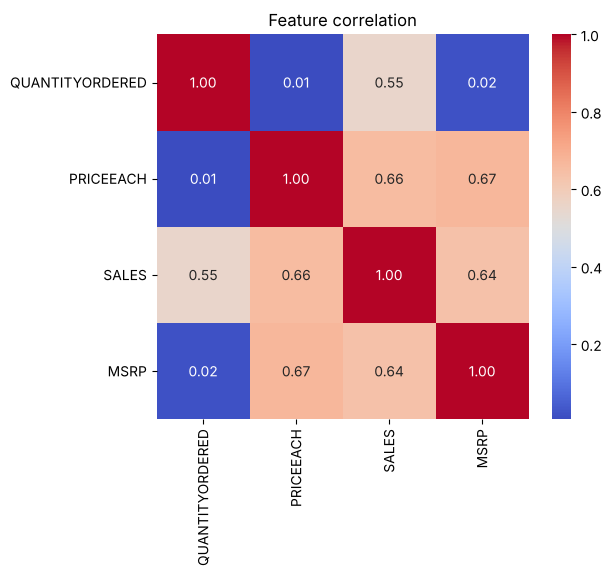

In [3]:
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"])
drop_cols = ["ADDRESSLINE1","ADDRESSLINE2","STATE","POSTALCODE","TERRITORY",
             "PHONE","CONTACTFIRSTNAME","CONTACTLASTNAME","CUSTOMERNAME","ORDERNUMBER"]
df = df.drop(columns=drop_cols)
print("Remaining columns:", list(df.columns))

features = ["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]
X = df[features]
X_scaled = StandardScaler().fit_transform(X)

plt.figure(figsize=(6,5))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f"); plt.title("Feature correlation"); plt.show()

## 2. Elbow method

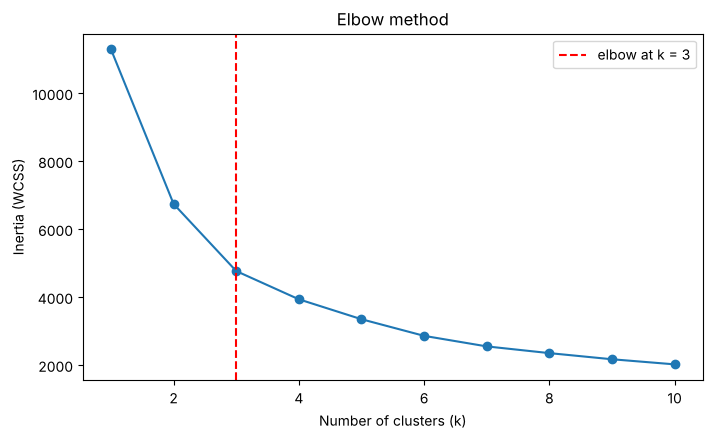

 k  inertia
 1  11292.0
 2   6741.7
 3   4766.0
 4   3934.9
 5   3348.3
 6   2858.8
 7   2548.5
 8   2350.7
 9   2170.0
10   2019.8

Elbow detected at k = 3


In [4]:
K_range = range(1, 11)
inertia = []
for k in K_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    inertia.append(km.inertia_)

# Elbow = point with the largest distance from the straight line joining first and last point
p1, p2 = np.array([1, inertia[0]]), np.array([10, inertia[-1]])
dist = []
for k, w in zip(K_range, inertia):
    p = np.array([k, w])
    dist.append(abs((p2[0]-p1[0])*(p1[1]-p[1]) - (p1[0]-p[0])*(p2[1]-p1[1])) / np.linalg.norm(p2 - p1))
elbow_k = list(K_range)[int(np.argmax(dist))]

plt.figure(figsize=(8,4.5))
plt.plot(K_range, inertia, marker="o")
plt.axvline(elbow_k, color="r", ls="--", label=f"elbow at k = {elbow_k}")
plt.xlabel("Number of clusters (k)"); plt.ylabel("Inertia (WCSS)")
plt.title("Elbow method"); plt.legend(); plt.show()

print(pd.DataFrame({"k": list(K_range), "inertia": np.round(inertia, 1)}).to_string(index=False))
print("\nElbow detected at k =", elbow_k)

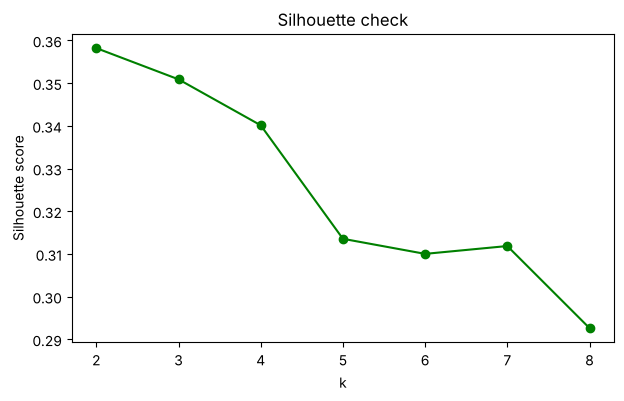

{2: 0.358, 3: 0.351, 4: 0.34, 5: 0.314, 6: 0.31, 7: 0.312, 8: 0.293}


In [5]:
sil = {k: silhouette_score(X_scaled, KMeans(k, n_init=10, random_state=42).fit_predict(X_scaled)) for k in range(2, 9)}
plt.figure(figsize=(7,4)); plt.plot(list(sil), list(sil.values()), marker="o", color="green")
plt.xlabel("k"); plt.ylabel("Silhouette score"); plt.title("Silhouette check"); plt.show()
print({k: round(v, 3) for k, v in sil.items()})

## 3. K-Means with the chosen k

In [6]:
kmeans = KMeans(n_clusters=elbow_k, n_init=10, random_state=42)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("Silhouette score:", round(silhouette_score(X_scaled, df["KMeans_Cluster"]), 3))
print("\nCluster sizes:\n", df["KMeans_Cluster"].value_counts().sort_index())
df.groupby("KMeans_Cluster")[features].mean().round(2)

Silhouette score: 0.351

Cluster sizes:
 KMeans_Cluster
0    975
1    852
2    996
Name: count, dtype: int64


,QUANTITYORDERED,PRICEEACH,SALES,MSRP
KMeans_Cluster,,,,
0,35.21,59.55,2101.08,64.15
1,43.72,97.48,5720.08,127.89
2,27.60,95.44,3123.06,113.27


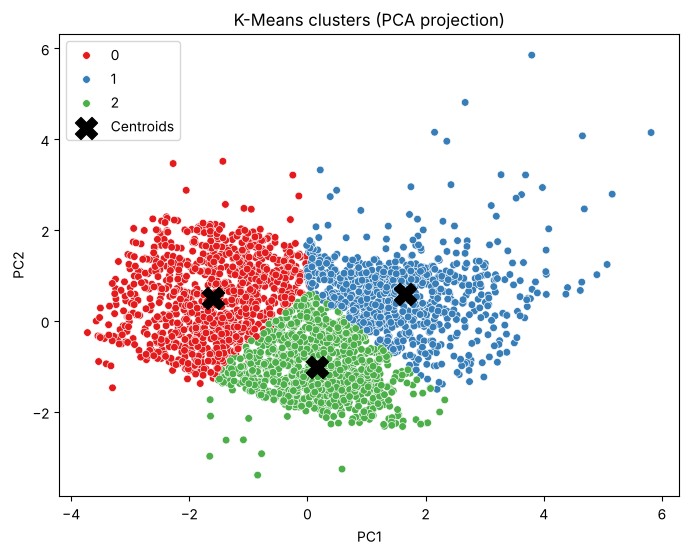

Variance explained by 2 PCs: 0.887


In [7]:
pca = PCA(n_components=2, random_state=42)
pts = pca.fit_transform(X_scaled)
centers = pca.transform(kmeans.cluster_centers_)
plt.figure(figsize=(8,6))
sns.scatterplot(x=pts[:,0], y=pts[:,1], hue=df["KMeans_Cluster"], palette="Set1", s=30)
plt.scatter(centers[:,0], centers[:,1], c="black", s=250, marker="X", label="Centroids")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.title("K-Means clusters (PCA projection)"); plt.legend(); plt.show()
print("Variance explained by 2 PCs:", pca.explained_variance_ratio_.sum().round(3))

## 4. Hierarchical clustering (for comparison)

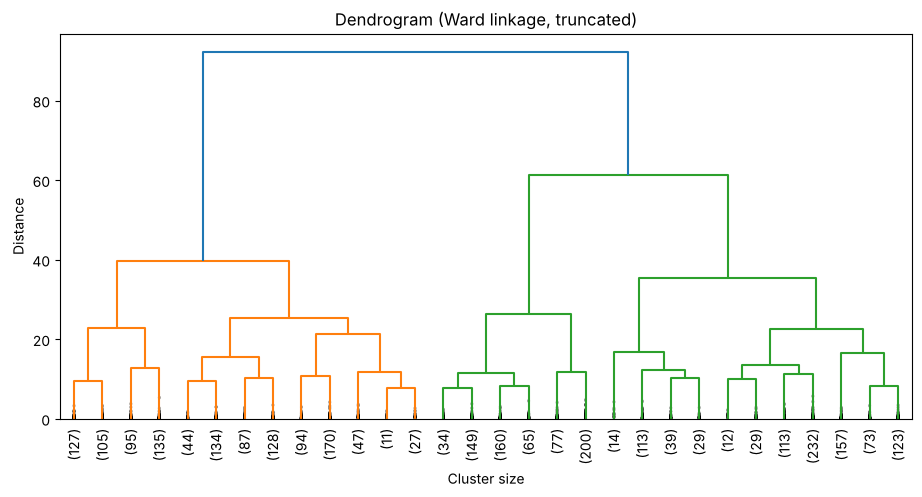

Hierarchical silhouette: 0.315
              QUANTITYORDERED  PRICEEACH    SALES    MSRP
Hier_Cluster                                             
0                       35.48      63.75  2273.01   70.55
1                       41.71      99.29  5575.63  127.05
2                       25.39      97.35  3048.60  117.84

Agreement with K-Means (cross-tab):


Hier_Cluster,0,1,2
KMeans_Cluster,,,
0,971,3,1
1,86,761,5
2,147,170,679


In [8]:
Z = linkage(X_scaled, method="ward")
plt.figure(figsize=(11,5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., show_contracted=True)
plt.title("Dendrogram (Ward linkage, truncated)"); plt.xlabel("Cluster size"); plt.ylabel("Distance"); plt.show()

agg = AgglomerativeClustering(n_clusters=elbow_k, linkage="ward")
df["Hier_Cluster"] = agg.fit_predict(X_scaled)
print("Hierarchical silhouette:", round(silhouette_score(X_scaled, df["Hier_Cluster"]), 3))
print(df.groupby("Hier_Cluster")[features].mean().round(2))
print("\nAgreement with K-Means (cross-tab):")
pd.crosstab(df["KMeans_Cluster"], df["Hier_Cluster"])

## Conclusion
- The elbow is at **k = 3**; the silhouette score (0.351) is similar to k = 2 (0.358), so 3 segments is a reasonable choice.
- The clusters differ mainly in product price and order value (`PRICEEACH`, `MSRP`, `SALES`):
  - **Cluster 0**: low-priced products, low sales (avg SALES ≈ 2,101)
  - **Cluster 2**: high-priced products, smaller quantities, mid sales (avg SALES ≈ 3,123)
  - **Cluster 1**: high-priced products, large quantities, highest sales (avg SALES ≈ 5,720)
- Hierarchical (Ward) clustering gives very similar segments (silhouette 0.315 vs 0.351 for K-Means); the cross-tab shows most orders land in matching groups.